Shape: (8000, 2)
Missing values:
 text     0
label    0
dtype: int64


<Figure size 600x400 with 0 Axes>

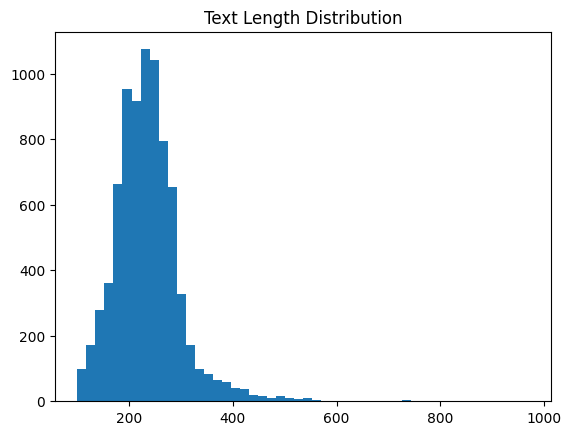

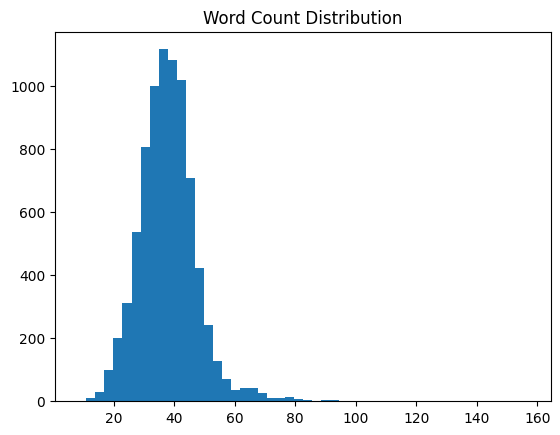

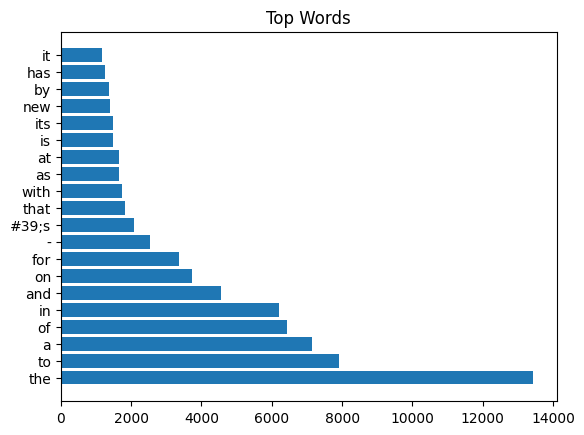

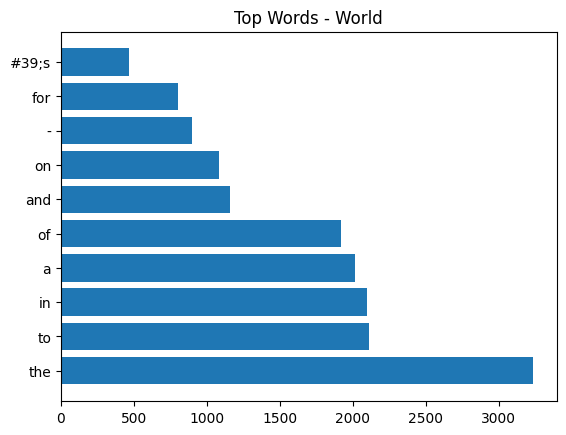

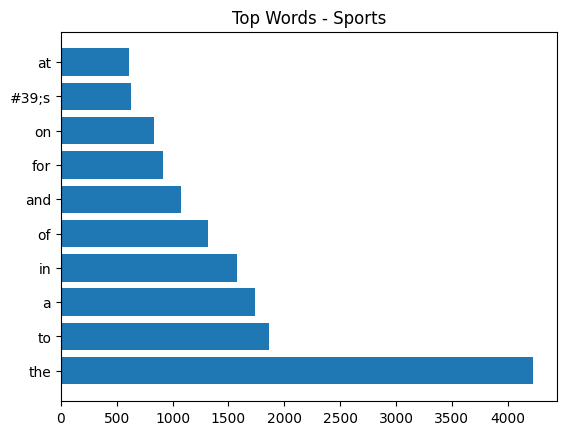

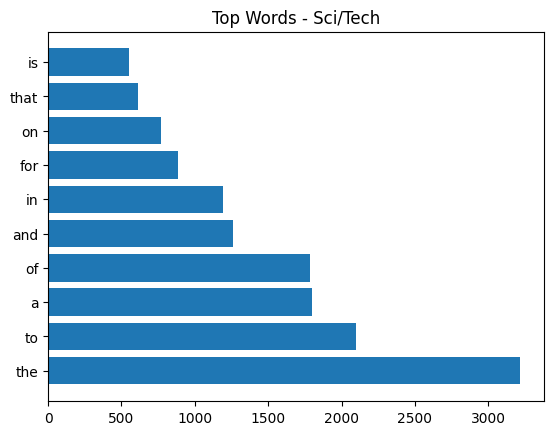

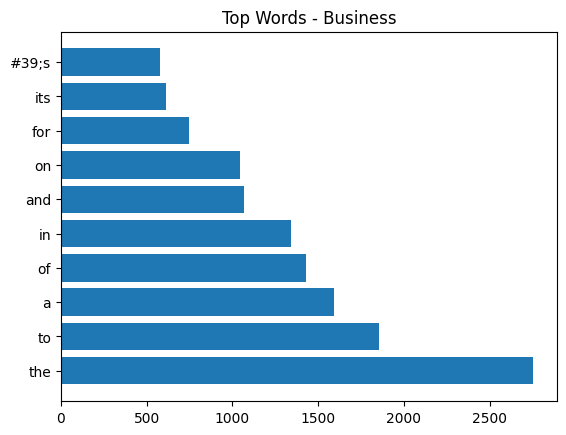

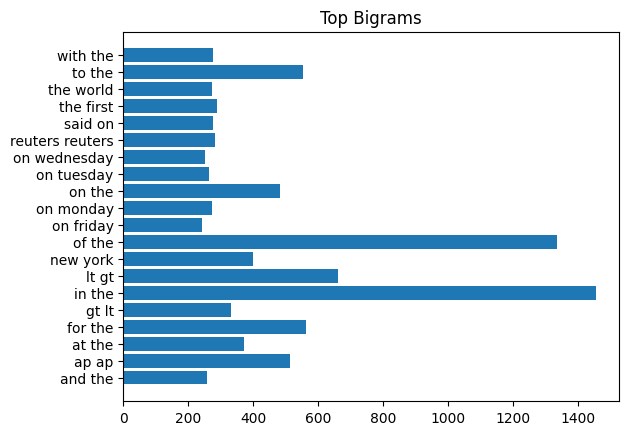

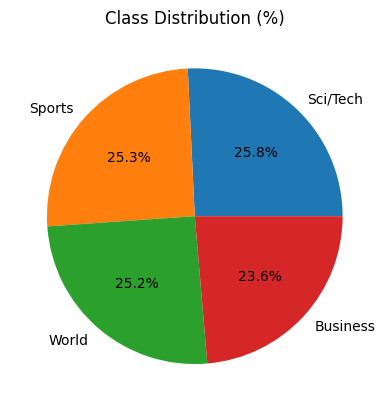

In [ ]:
# Imports
from datasets import load_dataset
from data_loader import load_data
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

plt.figure(figsize=(6,4))

# Load data
X_train, X_test, y_train, y_test = load_data()
df = pd.DataFrame({
    'text': X_train, 
    'label': y_train
})

print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())

# Label names
labels = ["World", "Sports", "Business", "Sci/Tech"]
df['label_name'] = df['label'].map(dict(enumerate(labels)))

# Text Length
df['text_length'] = df['text'].apply(len)
plt.figure()
plt.hist(df['text_length'], bins=50)
plt.title("Text Length Distribution")
plt.show()

# Word Count
df['word_count'] = df['text'].apply(lambda x: len(x.split()))
plt.figure()
plt.hist(df['word_count'], bins=50)
plt.title("Word Count Distribution")
plt.show()

# Top Words
words = " ".join(df['text']).lower().split()
common = Counter(words).most_common(20)
w, c = zip(*common)

plt.figure()
plt.barh(w, c)
plt.title("Top Words")
plt.show()

# Top words per class
for label in df['label_name'].unique():
    text = " ".join(df[df['label_name']==label]['text']).lower().split()
    common = Counter(text).most_common(10)
    w, c = zip(*common)

    plt.figure()
    plt.barh(w, c)
    plt.title(f"Top Words - {label}")
    plt.show()

# Bigram
vec = CountVectorizer(ngram_range=(2,2), max_features=20)
X = vec.fit_transform(df['text'])

words = vec.get_feature_names_out()
counts = X.sum(axis=0).A1

plt.figure()
plt.barh(words, counts)
plt.title("Top Bigrams")
plt.show()

# Pie Chart
plt.figure()
df['label_name'].value_counts().plot.pie(autopct='%1.1f%%')
plt.title("Class Distribution (%)")
plt.ylabel("")
plt.show()